In [1]:
import matplotlib.pyplot as plt
import numpy as np
# import cv2 as cv
import pandas as pd
import anndata as ad
import os,sys,re
import seaborn as sns

## Xenium IHC Data

In [4]:
import tifffile
from ome_types import from_xml
img_dir = '/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial/ihc'
with tifffile.TiffFile(os.path.join(img_dir,'GSE311609_ihc_breast_breast_B4_B4_breast_breast_B1_B1_2.ome.tif')) as tif:
    series = tif.series[0]

    print("full shape:", series.shape)
    print(tif.ome_metadata)
    metadata = from_xml(tif.ome_metadata)
    print(metadata)

    for i, level in enumerate(series.levels):
        print(i, level.shape)
    xenium_img = series.levels[3].asarray()

# image_data = tifffile.imread(os.path.join(img_dir,'GSE311609_ihc_breast_breast_B4_B4_breast_breast_B1_B1_2.ome.tif'),is_ome=False, is_mmstack=False, is_imagej=False)

full shape: (8, 50400, 34560)
<?xml version="1.0" encoding="UTF-8" standalone="no"?><!-- Warning: this comment is an OME-XML metadata block, which contains crucial dimensional parameters and other important metadata. Please edit cautiously (if at all), and back up the original data before doing so. For more information, see the OME-TIFF web site: https://docs.openmicroscopy.org/latest/ome-model/ome-tiff/. --><OME xmlns="http://www.openmicroscopy.org/Schemas/OME/2016-06" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" Creator="OME Bio-Formats 7.0.1" UUID="urn:uuid:309c87af-779f-43f9-8062-32a2c278125f" xsi:schemaLocation="http://www.openmicroscopy.org/Schemas/OME/2016-06 http://www.openmicroscopy.org/Schemas/OME/2016-06/ome.xsd"><Image ID="Image:0"><Pixels BigEndian="true" DimensionOrder="XYCZT" ID="Pixels:0" Interleaved="false" PhysicalSizeX="0.49616675835479207" PhysicalSizeXUnit="µm" PhysicalSizeY="0.49616675835479207" PhysicalSizeYUnit="µm" SizeC="8" SizeT="1" SizeX="34560" Siz

In [35]:
colors = [im.color for im in metadata.images[0].pixels.channels]

In [3]:
import tifffile
from ome_types import from_xml
img_dir = '/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial'
with tifffile.TiffFile(os.path.join(img_dir,'GSM9509173_breast_breast_B1_B1_2_morphology_focus.ome.tif')) as tif:
    series = tif.series[0]

    print("full shape:", series.shape)
    print(tif.ome_metadata)
    metadata = from_xml(tif.ome_metadata)
    print(metadata)

    for i, level in enumerate(series.levels):
        print(i, level.shape)
    img = series.levels[5].asarray()


full shape: (27253, 36949)
<OME xmlns="http://www.openmicroscopy.org/Schemas/OME/2016-06" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" Creator="tifffile.py 2022.10.10" UUID="urn:uuid:6c84291e-5334-11ee-a665-3cecefd5e156" xsi:schemaLocation="http://www.openmicroscopy.org/Schemas/OME/2016-06 http://www.openmicroscopy.org/Schemas/OME/2016-06/ome.xsd">
    <Plate ID="Plate:1" WellOriginX="-0.0" WellOriginXUnit="µm" WellOriginY="-0.0" WellOriginYUnit="µm" />
    <Instrument ID="Instrument:1">
        <Microscope Manufacturer="10x Genomics" Model="Xenium" />
    </Instrument>
    <Image ID="Image:0" Name="Image0">
        <InstrumentRef ID="Instrument:1" />
        <Pixels DimensionOrder="XYZCT" ID="Pixels:0" SizeC="1" SizeT="1" SizeX="36949" SizeY="27253" SizeZ="1" Type="uint16" PhysicalSizeX="0.2125" PhysicalSizeY="0.2125">
            <Channel ID="Channel:0:0" Name="DAPI" SamplesPerPixel="1" />
            <TiffData PlaneCount="1" />
        </Pixels>
    </Image>
</OME>
plates=[

In [29]:
metadata.images[0].pixels.channels[0]

Channel(
   id='Channel:0:0',
   name='DAPI',
   samples_per_pixel=1,
)

In [4]:
DAPI_CHANNEL = 0
IHC_PIXEL_SIZE = 0.49616675835479207  # µm / pixel
IHC_LEVEL = 5
DOWNSAMPLE = 2 ** IHC_LEVEL  # 32
IHC_LEVEL5_PIXEL_SIZE = IHC_PIXEL_SIZE * DOWNSAMPLE
# 15.877336... µm / pixel

<tifffile.TiffPageSeries 0 ome>

In [30]:

import matplotlib.pyplot as plt
ihc_path = '/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial/ihc/GSE311609_ihc_breast_breast_B4_B4_breast_breast_B1_B1_2.ome.tif'
with tifffile.TiffFile(ihc_path) as tif:
    xenium_dapi = tif.series[0].levels[5][0].asarray()

ihc_path = '/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial/GSM9509173_breast_breast_B1_B1_2_morphology_focus.ome.tif'

with tifffile.TiffFile(ihc_path) as tif:
    ihc_dapi = tif.series[0].levels[5].asarray()
ihc_dapi

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       [0, 2, 3, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(851, 1154), dtype=uint16)

In [37]:
ihc_dapi,xenium_dapi

(array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 1, ..., 0, 0, 0],
        [0, 2, 3, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(851, 1154), dtype=uint16),
 array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(1575, 1080), dtype=uint8))

In [38]:
import numpy as np
from skimage.registration import phase_cross_correlation
from scipy.ndimage import shift
import cv2

# Load images

# Calculate translation shift with subpixel precision (upsample factor 100)
detected_shift, error, diffphase = phase_cross_correlation(
    xenium_dapi, ihc_dapi, upsample_factor=100
)

# Apply shift to the moving image to align it
# detected_shift returns [y_shift, x_shift]
registered_img = shift(ihc_dapi, shift=detected_shift)

print(f"Detected Pixel Shift (Y, X): {detected_shift}")

ValueError: images must be same shape

(1703, 2309)


(np.float64(7887.314930725098),
 np.float64(-232.8547561645508),
 np.float64(-52.509365844726574),
 np.float64(5301.3974884033205))

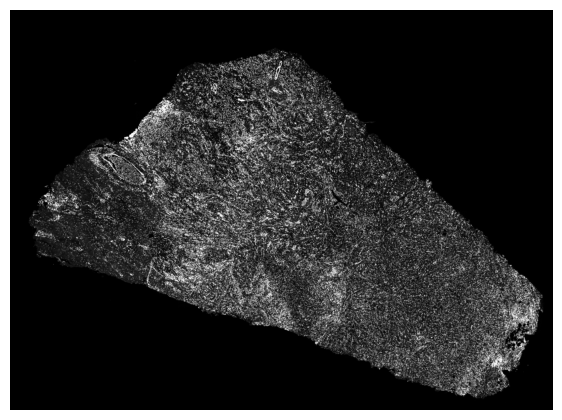

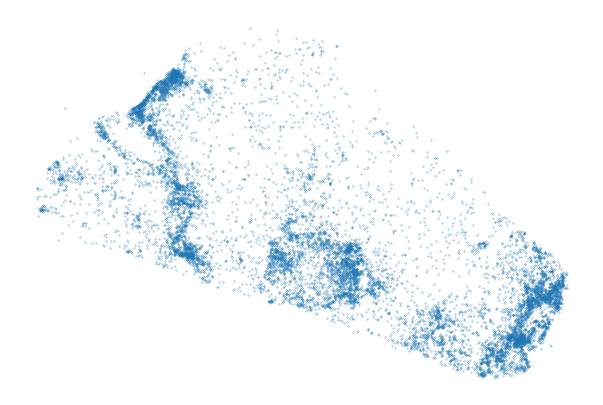

In [8]:
import tifffile
import numpy as np
import matplotlib.pyplot as plt
ihc_path = '/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial/ihc/GSE311609_ihc_breast_breast_B4_B4_breast_breast_B1_B1_2.ome.tif'
ihc_path = '/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial/GSM9509173_breast_breast_B1_B1_2_morphology_focus.ome.tif'

with tifffile.TiffFile(ihc_path) as tif:
    ihc_dapi = tif.series[0].levels[4].asarray()
print(ihc_dapi.shape)
lo, hi = np.percentile(ihc_dapi, [1, 99.5])

fig, ax = plt.subplots(figsize=(7, 10))
ax.imshow(
    ihc_dapi,
    cmap="gray",
    vmin=lo,
    vmax=hi,
)
ax.axis("off")
ax.invert_xaxis()
ax.invert_yaxis()
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    st_data.obs["x_centroid"],
    st_data.obs["y_centroid"],
    s=.05,
    rasterized=True,
)

ax.set_aspect("equal")
ax.invert_xaxis()
ax.axis("off")

In [36]:
colors

[Color('#fff0', rgb=(255, 255, 255, 0.0)),
 Color('#ff00', rgb=(255, 255, 0, 0.0)),
 Color('#f000', rgb=(255, 0, 0, 0.0)),
 Color('#0000', rgb=(0, 0, 0, 0.0)),
 Color('#0ff0', rgb=(0, 255, 255, 0.0)),
 Color('#ff800000', rgb=(255, 128, 0, 0.0)),
 Color('#f0f0', rgb=(255, 0, 255, 0.0)),
 Color('#0f00', rgb=(0, 255, 0, 0.0))]

(8, 6300, 4320)


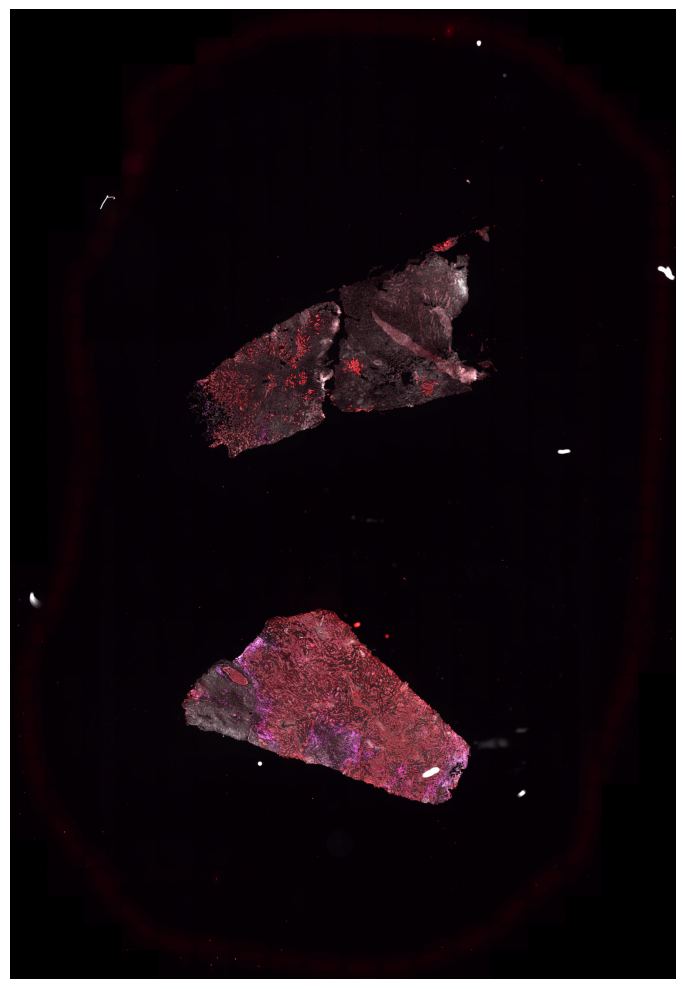

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
weights = np.array([
    1.0,  # DAPI
    0,  # Opal 570
    1,  # Opal 690
    0.0,  # AF
    0,  # Opal 480
    0,  # Opal 620
    1,  # Opal 780
    0,  # Opal 520
])
# RGB colors from the OME metadata
colors = np.array([
    [255, 255, 255],  # DAPI
    [255, 255,   0],  # Opal 570
    [255,   0,   0],  # Opal 690
    [  0,   0,   0],  # Sample AF
    [  0, 255, 255],  # Opal 480
    [255, 128,   0],  # Opal 620
    [255,   0, 255],  # Opal 780
    [  0, 255,   0],  # Opal 520
], dtype=float) / 255

rgb = np.zeros((*xenium_img.shape[1:], 3), dtype=float)
print(xenium_img.shape)
for c in range(xenium_img.shape[0]):
    x = xenium_img[c].astype(float)

    # Normalize each channel independently
    lo, hi = np.percentile(x, [0.01, 99.95])
    x = np.clip((x - lo) / (hi - lo), 0, 1)

    # Add this channel using its OME color
    rgb += weights[c]* x[..., None] * colors[c]

# Clip overlapping channels
rgb = np.clip(rgb, 0, 1)

plt.figure(figsize=(10, 10))
plt.imshow(rgb)
plt.axis("off")
plt.tight_layout()

In [6]:
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/final/GSM9509173_breast_breast_B1_B1_2_rctd_annotated.h5ad')
# st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/raw/spatial/GSM9509173_breast_breast_B1_B1_2.h5ad')

In [7]:
st_data = st_data[st_data.obs['harmony_cell_type'].str.contains('T')]

In [65]:
st_data

AnnData object with n_obs × n_vars = 141262 × 277
    obs: 'cell_id', 'cells_parquet_matched', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'sample_id', 'gsm_accession', 'source_h5', 'source_cells_parquet', 'xenium_n_umi', 'rctd_input_pass', 'rctd_spot_class', 'rctd_first_type', 'rctd_second_type', 'rctd_first_class', 'rctd_second_class', 'rctd_first_assignment_class_only', 'rctd_second_assignment_class_only', 'rctd_min_score', 'rctd_singlet_score', 'rctd_secondary_removed_for_singlet', 'rctd_first_weight', 'rctd_second_weight', 'batch', 'harmony_cell_type', 'split_X_primary_cell_type', 'split_X_w1_primary', 'split_X_first_type', 'split_X_purification_status', 'split_X_n_cell_types'
    var: 'feature_name', 'feature_type', 'genome', 'id', 'name', 'feature'
    uns: 'rctd_cell_type_names', 'rctd_class_df', 'rctd_postprocessing', 

In [58]:
tcell_coords = st_data.obs[['x_centroid','y_centroid']].values
tcell_coords

array([[ 880.82800293, 1694.83703613],
       [ 826.81384277, 1668.14331055],
       [ 829.07012939, 1673.80993652],
       ...,
       [5002.94140625, 1616.51342773],
       [5000.66552734, 1620.06103516],
       [5006.08544922, 1607.8371582 ]], shape=(141262, 2))

978 845
[7573.92333984 5204.37646484]


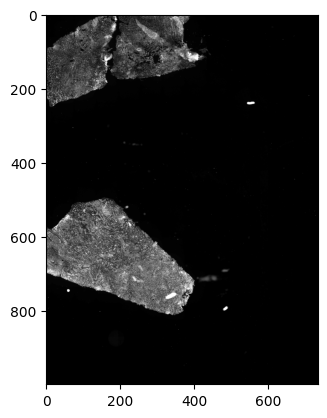

In [71]:
import matplotlib.pyplot as plt
import sys
sys.path.append('/home/jwinchel/Syndri/code')
import cv2 as cv
(x,y) = tcell_coords[500].astype(int)
print(x,y)

print(tcell_coords.max(axis=0))
crop_size=500
img_crop = img[0,x-crop_size:x+crop_size,y-crop_size:y+crop_size]

# img_crop = img
plt.imshow(img_crop,cmap='Grays_r',vmax=100)

## NSCLC CosMx 

In [12]:
# parse images
img_dir = '/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-RawMorphologyImages/'
files = sorted([f for f in os.listdir(img_dir)])
print(len(files)/9)
img_df = pd.DataFrame({'filename':files})
img_df['Run_Tissue_name'] = img_dir.split('/')[-3]
img_df['fov'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-2][1:]))
img_df['z'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-1][1:]))
img_df['filepath'] = img_df['filename'].apply(lambda x: os.path.join(img_dir,x))
img_df.head()

32.0


,filename,Run_Tissue_name,fov,z,filepath
0,20210907_180607_S1_C902_P99_N99_F001_Z001.TIF,Lung5_Rep1,1,1,/work/magroup/skrieger/Syndri/data/datasets/ns...
1,20210907_180607_S1_C902_P99_N99_F001_Z002.TIF,Lung5_Rep1,1,2,/work/magroup/skrieger/Syndri/data/datasets/ns...
2,20210907_180607_S1_C902_P99_N99_F001_Z003.TIF,Lung5_Rep1,1,3,/work/magroup/skrieger/Syndri/data/datasets/ns...
3,20210907_180607_S1_C902_P99_N99_F001_Z004.TIF,Lung5_Rep1,1,4,/work/magroup/skrieger/Syndri/data/datasets/ns...
4,20210907_180607_S1_C902_P99_N99_F001_Z005.TIF,Lung5_Rep1,1,5,/work/magroup/skrieger/Syndri/data/datasets/ns...


In [13]:
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/final/st_integrated_slice-Lung5_Rep1.h5ad')
st_data.obs['fov'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30])

In [18]:
gene_mapping = dict(zip(st_data.var['gene_symbol'].values,st_data.var['gene_ensembl'].values))
gene_mapping

{'ADGRL4': 'ENSG00000162618',
 'MZB1': 'ENSG00000170476',
 'MS4A4A': 'ENSG00000110079',
 'BST1': 'ENSG00000109743',
 'TEK': 'ENSG00000120156',
 'BTK': 'ENSG00000010671',
 'B3GNT7': 'ENSG00000156966',
 'MEG3': 'ENSG00000214548',
 'PTGS1': 'ENSG00000095303',
 'RSPO2': 'ENSG00000147655',
 'TNFRSF13B': 'ENSG00000240505',
 'IL13RA1': 'ENSG00000131724',
 'STAT1': 'ENSG00000115415',
 'ADIRF': 'ENSG00000148671',
 'CYTOR': 'ENSG00000222041',
 'MT1X': 'ENSG00000187193',
 'MERTK': 'ENSG00000153208',
 'INHA': 'ENSG00000123999',
 'HCST': 'ENSG00000126264',
 'KRT17': 'ENSG00000128422',
 'FOXF1': 'ENSG00000103241',
 'HDAC3': 'ENSG00000171720',
 'NRG1': 'ENSG00000157168',
 'RARG': 'ENSG00000172819',
 'SQSTM1': 'ENSG00000161011',
 'ANGPTL1': 'ENSG00000116194',
 'KRT20': 'ENSG00000171431',
 'NOTCH3': 'ENSG00000074181',
 'ADGRF5': 'ENSG00000069122',
 'IFI27': 'ENSG00000165949',
 'CFLAR': 'ENSG00000003402',
 'LAG3': 'ENSG00000089692',
 'LGALS9': 'ENSG00000168961',
 'OLFM4': 'ENSG00000102837',
 'IL17A': 'E

In [117]:
import pickle
import sys
sys.path.append('/home/jwinchel/Syndri/Heimdall/')

from Heimdall.utils import convert_to_ensembl_ids
# load transcript data
tx_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_tx_file.csv')

# Unpickling (loading from a file)
# with open('/home/jwinchel/Syndri/nsclc_playground/gene_mapping.pickle', 'rb') as f:
#     gene_mapping = pickle.load(f)


tx_df['gene_id_ensembl'] = tx_df['target'].map(gene_mapping)
tx_df['gene_id_ensembl'] = tx_df['gene_id_ensembl'].apply(lambda x: x[0] if isinstance(x,list) else x)
cell_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')
st_data = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/results/final/st_integrated_slice-Lung5_Rep1.h5ad')
l5r1_metadata = pd.read_csv('/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-Flat_files_and_images/Lung5_Rep1_metadata_file.csv')

st_data = st_data[st_data.obs['Run_Tissue_name']=='Lung5_Rep1']
st_data.obs = st_data.obs.merge(l5r1_metadata[['fov','cell_ID','CenterX_local_px',
       'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px']],on=['fov','cell_ID'])
st_data.obs['cell_type'] = st_data.obs['cell_type'].astype(str)
st_data.obs.loc[st_data.obs['cell_type'].str.startswith('tumor'),'cell_type'] = 'tumor'

# load a single fov
tx_df = tx_df[tx_df['fov'] == 26].reset_index(drop=True)
cell_df = cell_df[cell_df['fov'] == 26].reset_index(drop=True)
cell_df.head()

,fov,cell_ID,Area,AspectRatio,CenterX_local_px,CenterY_local_px,CenterX_global_px,CenterY_global_px,Width,Height,Mean.MembraneStain,Max.MembraneStain,Mean.PanCK,Max.PanCK,Mean.CD45,Max.CD45,Mean.CD3,Max.CD3,Mean.DAPI,Max.DAPI
0,26,1,8859,0.74,69,3587,3257.888889,177053.666667,91,123,2050,6362,37591,65361,283,814,0,40,1735,14155
1,26,2,2176,1.97,160,3629,3348.888889,177095.666667,77,39,1900,4514,26922,65307,279,694,0,10,6913,18315
2,26,3,2919,1.76,269,3624,3457.888889,177090.666667,86,49,2777,5971,34711,65308,318,813,0,30,4035,15765
3,26,4,4894,0.94,638,3606,3826.888889,177072.666667,80,85,2855,7216,43481,65307,417,900,0,114,1391,15116
4,26,5,5079,1.39,894,3611,4082.888889,177077.666667,104,75,2546,5957,30951,65281,326,795,0,32,2120,15327


In [119]:
sample_cells = cell_df[cell_df['cell_ID'].isin([535,1715,2875])].reset_index(drop=True)

In [120]:
# tumor genes taken from Mitchel et al
tumor_genes = ["KRT19", "KRT8", "KRT18", "TACSTD2", "CEACAM6", "CDH1", "EPCAM",
    "CLDN4", "SFN", "PHLDA2", "DDR1", "AGR2", "KRT6A", "KRT17",
    "CD24", "KRT5", "AQP3", "SLC2A1", "KRT7", "COL17A1", "FASN",
    "KRT15", "ITGA2", "ERBB3", "S100A2", "SPINK1", "ITGB4", "PIGR",
    "SOX2", "ITGA3", "CYSTM1", "NTRK2", "MAPK13", "CCND1", "HDAC1", "EGFR"]
fib_genes = ['MYL9','CXCL12','PDGFRB','RARRES2']
tx_df['is_marker'] = "N/A"
tx_df.loc[tx_df['target'].isin(tumor_genes),'is_marker'] = 'tumor'
tx_df.loc[tx_df['target'].isin(fib_genes),'is_marker'] = 'fibroblast'

In [121]:
img_df[img_df["fov"] == 26].iloc[3]

filename               20210907_180607_S1_C902_P99_N99_F026_Z004.TIF
Run_Tissue_name                                           Lung5_Rep1
fov                                                               26
z                                                                  4
filepath           /work/magroup/skrieger/Syndri/data/datasets/ns...
Name: 228, dtype: object

In [162]:
sample_adata = st_data[st_data.obs['cell_ID'].isin([535,1715,2875])&(st_data.obs['fov']==26)]
sample_adata.var.index = sample_adata.var.index.astype(str)
# tumor_subset = sample_adata.var[sample_adata.var['gene_symbol'].isin(tumor_genes)]['gene_ensembl'].values
# sample_adata = sample_adata[:,tumor_subset]

/tmp/ipykernel_3881726/33586243.py:2: ImplicitModificationWarning: Trying to modify index of attribute `.var` of view, initializing view as actual.
  sample_adata.var.index = sample_adata.var.index.astype(str)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [176]:
import numpy as np
import pandas as pd

probs = sample_adata.layers["syndri_admix_probs_X"]

# Handle sparse matrix if necessary
if hasattr(probs, "toarray"):
    probs = probs.toarray()
    
gene_probs_df = pd.DataFrame({
    "cell_ID": np.repeat(sample_adata.obs["cell_ID"].to_numpy(), sample_adata.n_vars),
    "gene_symbol": np.tile(sample_adata.var["gene_symbol"].to_numpy(), sample_adata.n_obs),
    "gene_ensembl": np.tile(sample_adata.var["gene_ensembl"].to_numpy(), sample_adata.n_obs),
    "syndri_admix_prob": probs.ravel(),
})

gene_probs_df

,cell_ID,gene_symbol,gene_ensembl,syndri_admix_prob
0,535,ADGRL4,ENSG00000162618,0.0
1,535,MZB1,ENSG00000170476,0.0
2,535,MS4A4A,ENSG00000110079,0.0
3,535,BST1,ENSG00000109743,0.0
4,535,TEK,ENSG00000120156,0.0
...,...,...,...,...
2863,2875,PDGFRA,ENSG00000134853,0.0
2864,2875,HCAR3,ENSG00000255398,0.0
2865,2875,BMPR2,ENSG00000204217,0.0
2866,2875,ENG,ENSG00000106991,0.0


In [177]:
tx_removed_df = tx_df.merge(gene_probs_df,left_on=['cell_ID','target'],right_on=['cell_ID','gene_symbol'],how='left')

In [178]:

# tx_removed_df = tx_removed_df[(tx_removed_df['syndri_admix_prob'].fillna(0)>0.9)&(tx_removed_df['is_marker']=='tumor')]
tx_removed_df = tx_removed_df[(tx_removed_df['cell_ID']).isin([535,1715,2875])]
tx_removed_df['is_removed'] = tx_removed_df['syndri_admix_prob']>0.9
tx_removed_df

,fov,cell_ID,x_global_px,y_global_px,x_local_px,y_local_px,z,target,CellComp,gene_id_ensembl,is_marker,gene_symbol,gene_ensembl,syndri_admix_prob,is_removed
538376,26,535,5930.588889,176253.680967,2741.700000,2787.014300,3,HSP90AB1,Membrane,ENSG00000096384,N/A,HSP90AB1,ENSG00000096384,0.991917,True
538377,26,535,5941.788989,176319.566627,2752.900100,2852.899960,3,TYK2,Nuclear,ENSG00000105397,N/A,TYK2,ENSG00000105397,0.999926,True
538378,26,535,5911.963889,176287.758407,2723.075000,2821.091740,3,EZR,Membrane,ENSG00000092820,N/A,EZR,ENSG00000092820,0.999744,True
538379,26,535,5929.403289,176268.438167,2740.514400,2801.771500,3,NPPC,Cytoplasm,ENSG00000163273,N/A,NPPC,ENSG00000163273,0.999989,True
538380,26,535,5949.274389,176312.795207,2760.385500,2846.128540,3,HLA-C,Nuclear,ENSG00000204525,N/A,HLA-C,ENSG00000204525,0.857323,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1462946,26,2875,7555.151584,176487.316630,4366.262695,3020.649963,1,HBA1,Nuclear,ENSG00000206172,N/A,HBA1,ENSG00000206172,0.698400,False
1462947,26,2875,7503.644748,176486.966715,4314.755859,3020.300049,1,MZT2A,Nuclear,ENSG00000173272,N/A,MZT2A,ENSG00000173272,0.999938,True
1462948,26,2875,7547.871311,176460.678446,4358.982422,2994.011780,1,POU5F1,Membrane,ENSG00000204531,N/A,POU5F1,ENSG00000204531,0.950001,True
1462949,26,2875,7509.348850,176507.406657,4320.459961,3040.739990,1,HLA-B,Cytoplasm,ENSG00000234745,N/A,HLA-B,ENSG00000234745,0.145187,False


In [179]:
tx_removed_df['target'].unique()

array(['HSP90AB1', 'TYK2', 'EZR', 'NPPC', 'HLA-C', 'FN1', 'RGCC',
       'S100A6', 'CXCR5', 'MALAT1', 'MZT2A', 'PLAC8', 'IGFBP7', 'GAS6',
       'COL1A1', 'ITGB1', 'CALD1', 'HSP90B1', 'CD164', 'STAT6', 'TPM2',
       'CALM3', 'COL3A1', 'COL1A2', 'FZD7', 'THBS2', 'KRT18', 'COL9A1',
       'GPX1', 'PTGES', 'CDH11', 'XBP1', 'KRT13', 'KRT17', 'MMP7',
       'NegPrb8', 'HLA-DRB5', 'MAF', 'VSIR', 'KRT8', 'COL6A1', 'COL9A2',
       'CRIP1', 'ABL1', 'TAGLN', 'ST6GAL1', 'COL4A2', 'HSPA1B', 'MXRA8',
       'TNFRSF12A', 'COL6A2', 'TM4SF1', 'VIM', 'NEAT1', 'GLUD1', 'HLA-A',
       'COL8A1', 'DUSP1', 'BECN1', 'RPL37', 'IL15RA', 'CRP', 'S100P',
       'OLFM4', 'ANXA4', 'PTGDR2', 'COL17A1', 'VCAN', 'ADGRG1', 'CD274',
       'DDR1', 'SFN', 'S100B', 'CCND1', 'IFITM3', 'KRT19', 'KRT14', 'B2M',
       'GSN', 'HLA-B', 'MT1X', 'LGALS3BP', 'LYZ', 'IGF2R', 'COL4A1',
       'DCN', 'CSK', 'FGF1', 'ITGA1', 'TUBB', 'IL33', 'S100A4', 'SPOCK2',
       'JAK2', 'HTT', 'COL5A1', 'GDF6', 'DUSP5', 'KRT23', 'PTGS2',
   

<Axes: xlabel='cell_ID', ylabel='syndri_admix_prob'>

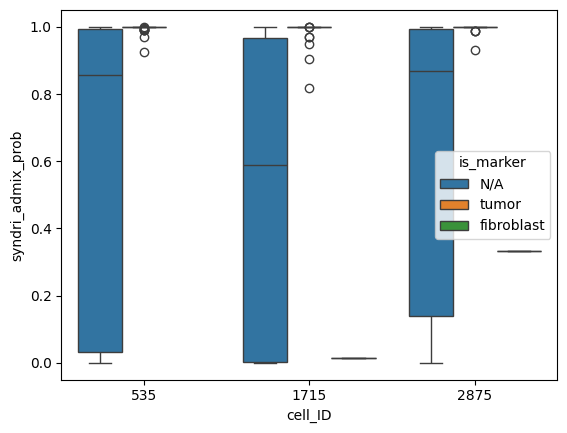

In [180]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=tx_removed_df,x='cell_ID',y='syndri_admix_prob',hue='is_marker')

32.0
[1, 2, 3, 4, 5, 6, 7, 8, 9]
3 1


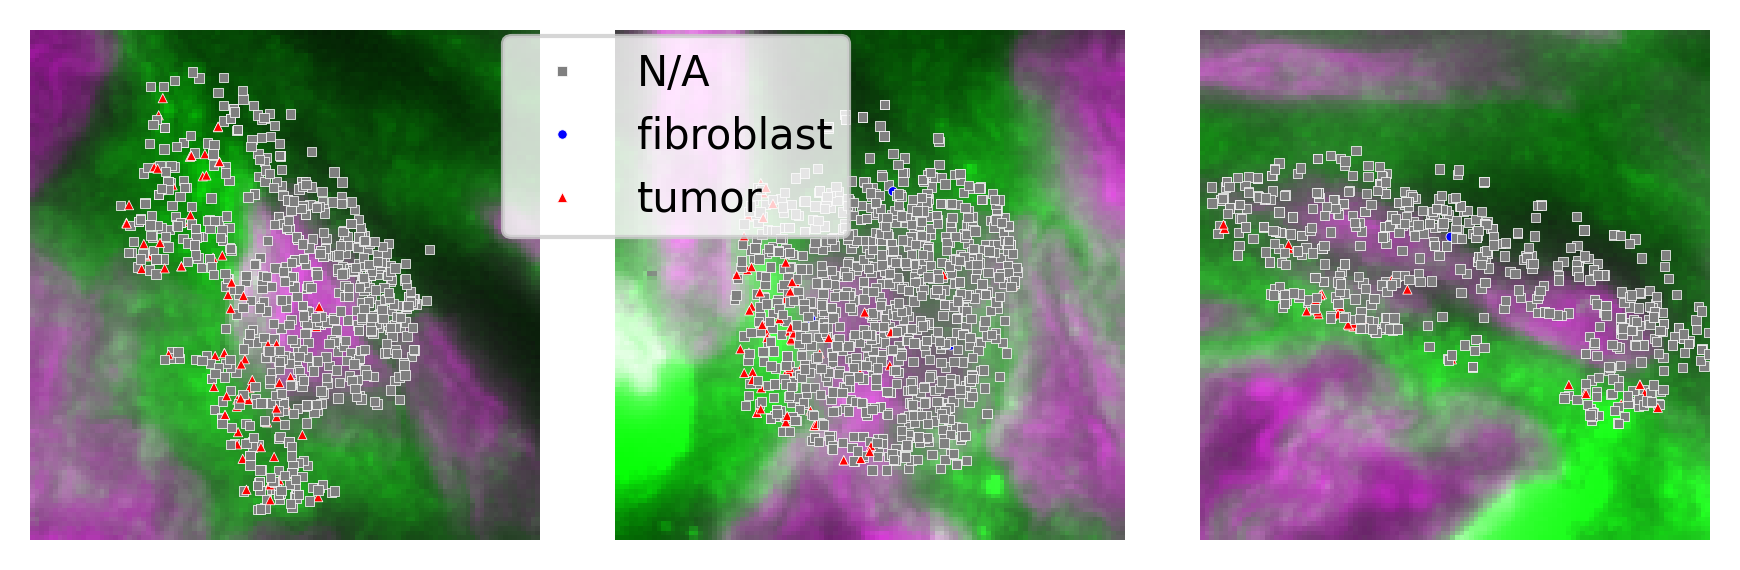

In [175]:
import tifffile
import importlib
import sys
sys.path.append('/home/jwinchel/Syndri/code')
from plotting import plot_cell_crops_with_tx, load_z_projected_image

importlib.reload(sys.modules['plotting'])
# parse images
img_dir = '/work/magroup/skrieger/Syndri/data/datasets/nsclc_cosmx/raw/spatial/Lung5_Rep1/Lung5_Rep1-RawMorphologyImages/'
files = sorted([f for f in os.listdir(img_dir)])
print(len(files)/9)
img_df = pd.DataFrame({'filename':files})
img_df['Run_Tissue_name'] = img_dir.split('/')[-3]
img_df['fov'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-2][1:]))
img_df['z'] = img_df['filename'].apply(lambda x: int(x.split('.')[0].split('_')[-1][1:]))
img_df['filepath'] = img_df['filename'].apply(lambda x: os.path.join(img_dir,x))
img_df.head()
# raw = tifffile.imread(img_df[img_df["fov"] == 26].iloc[4]["filepath"])  # (C,H,W)
# print(raw.shape)
raw = load_z_projected_image(img_df,fov=26)
#
marker_dict = {'tumor':'^','fibroblast':'o','N/A':'s'}
palette_dict = {'tumor':'red','fibroblast':'blue','N/A':'gray'}
fig, axes = plot_cell_crops_with_tx(
    raw,
    cell_df=sample_cells,
    tx_df=tx_df,
    n_cells=3,
    ncols=3,
    crop_size=110,
    label_col="is_marker",
    ch_purple=4,
    ch_green=0,
    y_origin="bottom",   
    s=5,
    random_state=None,
    dpi=300,
    figsize=(6,2),
    markers=marker_dict,
    palette=palette_dict,
)
# fig.legend(handles, labels, loc="upper center", ncol=2, frameon=True)
fig.tight_layout()
